Install the following python packages using your package manager of choice (pip in this case)

In [1]:
!pip install numpy==2.1
!pip install matplotlib
!pip install scipy
!pip install pandas
!pip install numba
!pip install plotly
!pip install bokeh
!pip install astropy
!pip install line_profiler
!pip install tqdm
!pip install ipyformkit==0.3.5
!pip install lxml
!pip install parse
!pip install pyinstrument

  Using cached numpy-2.1.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (60 kB)
Using cached numpy-2.1.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Not uninstalling numpy at /usr/local/autofs.home/home/hoppe/miniconda3/lib/python3.12/site-packages, outside environment /mnt/beegfs/gemini/groups/bergemann/users/hoppe/new_branch/m3dis/experiments/Multi3D/test-env
    Can't uninstall 'numpy'. No files were found to uninstall.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.59.1 requires numpy<1.27,>=1.22, but you have numpy 2.1.0 which is incompatible.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.1.0 which is incompatible.
  Using cached ipyformkit-0.3.5-py3-none-any.whl.metadata (7.6 kB)
Using cached ipyformkit

Import the `tumult` python package amongst other common packages

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tumult
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OMP_STACKSIZE'] = '256M'
plt.style.use('tumult/Bergemann2020.mplstyle')
#plt.style.use('tumult/Bergemann2023.mplstyle') # uncomment for serif axis labels
%config InlineBackend.figure_format='svg' # turns plots into vector graphics inside this notebook

Execute Multi by calling the Dispatch executable and supplying the default demo input parameter file `demo.nml`.
This will run a 1D solar Marcs model using a 6-Level toy Barium atom.

In [3]:
! ./dispatch.x demo.nml

OMP: Warning #182: OMP_STACKSIZE: ignored because KMP_STACKSIZE has been defined
 This version was compiled with default real KIND = 4
 MPI is not enabled!
 DISPATCH code framework, branch:tumult, hash:9464f9bae
 SOLVER=None OPTS=
 Intel(R) Version 2021.11.1 Build 20231117_000000  
 ================================ mpi_t%info ====================================
 n_sockets =   1
   n_cores =  36
 n_threads =   1
  n_places =  72
   n_ranks =   1
 Stacksize =   256MB
 This version was compiled with default real KIND = 4
 ================================= io_t%init ====================================
 parameters from: demo.nml
 output directory: data/demo/
 ============================ read_external_t%ini ===============================
FeH was overwritten by Marcs model: [Fe/H] =  0.00
Vmic was overwritten by Marcs model: Vmic =  1.00
Reading atom file: ./input_multi3d/atoms/atom.ba06
  - Reading collision data
Changing abundance of Ba from  2.17 to  2.11
sp_from_atom: frequency grid h

The default output directory is `./data/`. A new subfolder is created according to the name of your input parameter file. It can be opened and read as follows:

In [4]:
run = tumult.read('data/demo/')

Now we have created an object with the name of `run`. This object contains all of the data and meta-data of our demo run. We can obtain the spectral data by using the `get_spectrum` method. This will return a `Spectrum` object, which is a custom class that contains the wavelength and flux data, as well as the units of these quantities. Run `run.get_spectrum?` to see the available options for obtaining different spectra.

In [5]:
run.get_spectrum(imu=0, LTE=True)

,Å,erg Hz⁻¹ s⁻¹ sr⁻¹ cm⁻²
0,4552.818181,0.000033
1,4552.830327,0.000033
2,4552.842473,0.000033
3,4552.854619,0.000033
4,4552.866766,0.000033
...,...,...
799,6497.522157,0.000041
800,6497.528660,0.000041
801,6497.535163,0.000041
802,6497.541665,0.000041


We can also use the `crop` method to extract flux or intensity spectra (it calls get_spectrum internally). Here we extract the NLTE flux spectrum. To plot the resulting spectrum, we can use the built-in plot method:

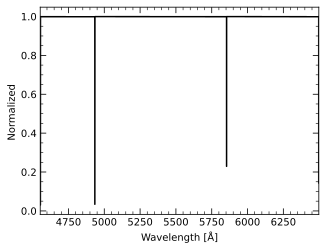

In [7]:
spec = run.crop()
spec.plot(color='black')

To zoom into a part of the spectrum one may do:

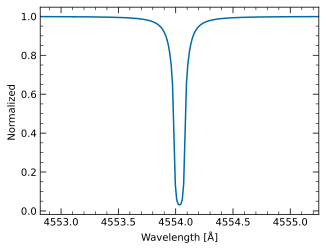

In [11]:
lam0 = 4554.033
dlam = 2.5
run.crop(x0=lam0, dx=2.5).plot()

We trim the underlying spectral data using the  `crop()` function of the `run` object. It has many useful arguments. Here I list the most important ones:
1. `x0`, `dx`: can be used in combination in order to crop the spectrum to a region around a central wavelength lam0.
2. `xmin`,`xmax`: alternatively one may pass xmin and xmax instead to crop the wavelengths.
3. `relative=False`: when one uses lam0 and dlam, the wavelength values are given as distance from lam0, but by setting relative=False, one can keep the original wavelengths.
4. `norm=False`: plots the unnormalised spectrum.
5. `imu=0`: plots the disk-center intensity, rather than the flux. By increasing imu, you can plot the various angles of the chosen angle quadrature of the run.
6. `vdop=1.5`: applies doppler broadening with a velocity of 1.5 km/s by convolving with a Gaussian profile.
7. `vshift=1.5`: doppler shifts the spectrum corresponding to a velocity of 1.5 km/s.
8. `LTE=True`: plots the LTE spectrum. By default it will try to plot the NLTE spectrum.


An array accessible via `run.line` contains multiple objects of the `trans_class`. This class makes plotting of spectral lines stored in the model atom very easy. Each run stores both LTE and NLTE spectra by default. Let's make a quick comparison:

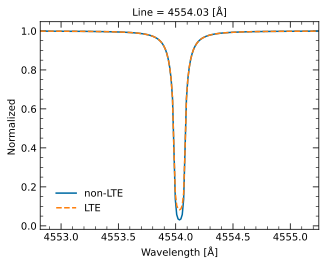

In [12]:
imu = None # None gives flux, use integers to plot intensities for different angles
norm = True # set to False for unnormalised line profile
ka = 0 # atom index
kr = 0 # line index

line = run.atoms[ka].line[kr]
line.crop(imu=imu, norm=norm, LTE=False).plot(linestyle='-', label='non-LTE')
line.crop(imu=imu, norm=norm, LTE=True).plot(linestyle='--', label='LTE')
plt.title(line.title)
plt.legend()

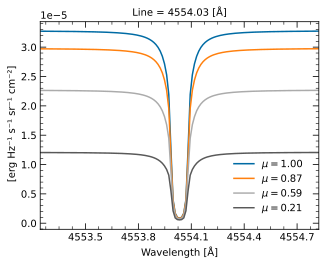

In [14]:
dlam = 0.8 # zooms into the line profile to ±dlam angstroms.
norm = False

# alternatively one may get the line object by its wavelength
line = run.get_line(4554.033)

 # iterate over all angles
for imu, mu in enumerate(run.mus):
  label = r'$\mu=${:.2f}'.format(mu)
  line.crop(imu=imu, norm=norm, dx=dlam).plot(label=label)

plt.title(line.title)
plt.legend()

Text(0.5, 1.0, 'Line = 4554.03 [Å]')

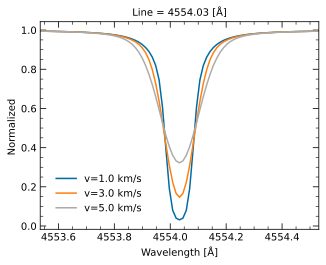

In [15]:
dlam = 0.5
imu = 0
line = run.get_line(4554.033)

 # convolve with doppler profiles
for vdop in [1.0, 3.0, 5.0]:
  label = 'v={:.1f} km/s'.format(vdop)
  line.crop(imu=imu, dx=dlam, vdop=vdop).plot(label=label)

plt.legend()
plt.title(line.title)

Let's download a 3D solar atmosphere snapshot from our website at nlte.mpia.de.

In [ ]:
from urllib import request
import zipfile
import os

# Define the URL and output paths
url = 'https://gemini-web.mpia.de/atmos3D/SunLTE_E_t57.77g44.40m0.000_v1.0/SunLTE_t5777_g4.440_z0.000_sn779_m3dis.zip'
out_dir = 'input_multi3d/atmos/'
tmp = out_dir + 'SunLTE_m3dis.zip'

# Download the file
print("Downloading...")
request.urlretrieve(url, tmp)
print("Download complete.")

# Unzip the file
print("Unzipping...")
with zipfile.ZipFile(tmp, 'r') as zip_ref:
    zip_ref.extractall(out_dir)
print("Unzipping complete.")

# remove the zip file
os.remove(tmp)

Now we can run the 3D example. This may take a while, depending on your machine. The output will be stored in data/demo3d/.

In [ ]:
! ./dispatch.x demo3d.nml